In [1]:
%load_ext autoreload
%autoreload 2

In [ ]:
import sys

sys.path.append("../..")

import json
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import seaborn as sns
import xarray as xr

from src.utils.utils_xarray import sel_extent
from src.utils.constants import EXTENT_BC, EXTENT_BC_MRRO, EXTENT_CH

sns.set_style("whitegrid", {"grid.color": ".93"})

In [3]:
paths = json.load(open("../../paths_so4.json"))
path_data_processed = Path(paths["path_data_processed"])
path_data_temporary = Path(paths["path_data_temporary"])
path_data_gcm = Path("/net/atmos/data/cmip5-ng/")

In [11]:
gcms = ["CNRM-CM5_r1i1p1", "HadGEM2-ES_r1i1p1", "NorESM1-M_r1i1p1", "MPI-ESM-LR_r1i1p1", "EC-EARTH_r12i1p1"]
ensemble_members = [gcm.split("_")[-1] for gcm in gcms]
gcms = [gcm.split("_")[0] for gcm in gcms]

In [43]:
var = "tas"
temp_res = "ann"
scenarios = ["rcp26", "rcp45", "rcp85"]

subset_gcms = []
for gcm, ens in zip(gcms, ensemble_members):
    for scenario in scenarios:
        subset_gcms.extend(sorted(path_data_gcm.glob(f"{var}/*{temp_res}_{gcm}_{scenario}_*{ens}*_g025.nc")))

len(subset_gcms)

15

In [44]:
all_other_gcms_data = []
for scenario in scenarios:
    all_other_gcms_data.extend(
        sorted(path_data_gcm.glob(f"{var}/*{temp_res}*{scenario}_*_g025.nc"))
    )
# Remove all elements in matches from all_other_gcms_data
all_other_gcms_data = [item for item in all_other_gcms_data if item not in subset_gcms]
len(all_other_gcms_data)

251

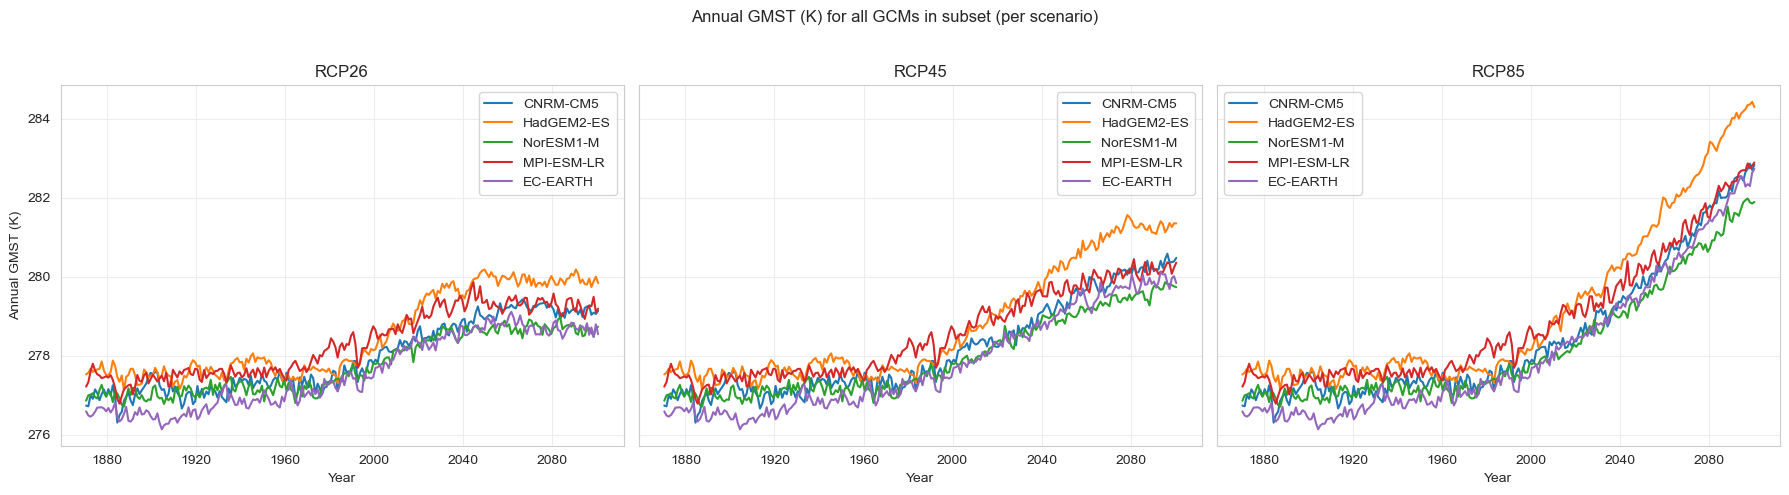

In [ ]:
fig, axes = plt.subplots(1, len(scenarios), figsize=(18, 5), sharey=True)

for i, scenario in enumerate(scenarios):
    ax = axes[i]
    for file in subset_gcms:
        if scenario in file.name:
            ds = xr.open_dataset(file)
            mean = ds[var].mean(dim=["lat", "lon"]).values
            years = ds["year"].values if "year" in ds else np.arange(len(mean))
            gcm = file.stem.split("_")[2]
            ax.plot(years, mean, label=gcm, alpha=1)
            ds.close()
    ax.set_xlabel("Year")
    if i == 0:
        ax.set_ylabel("Annual GMST (K)")
    ax.set_title(f"{scenario.upper()}")
    ax.legend()

fig.suptitle("Annual GMST for all GCMs in subset (per scenario)")
plt.tight_layout(rect=[0, 0, 1, 0.96])
plt.show()

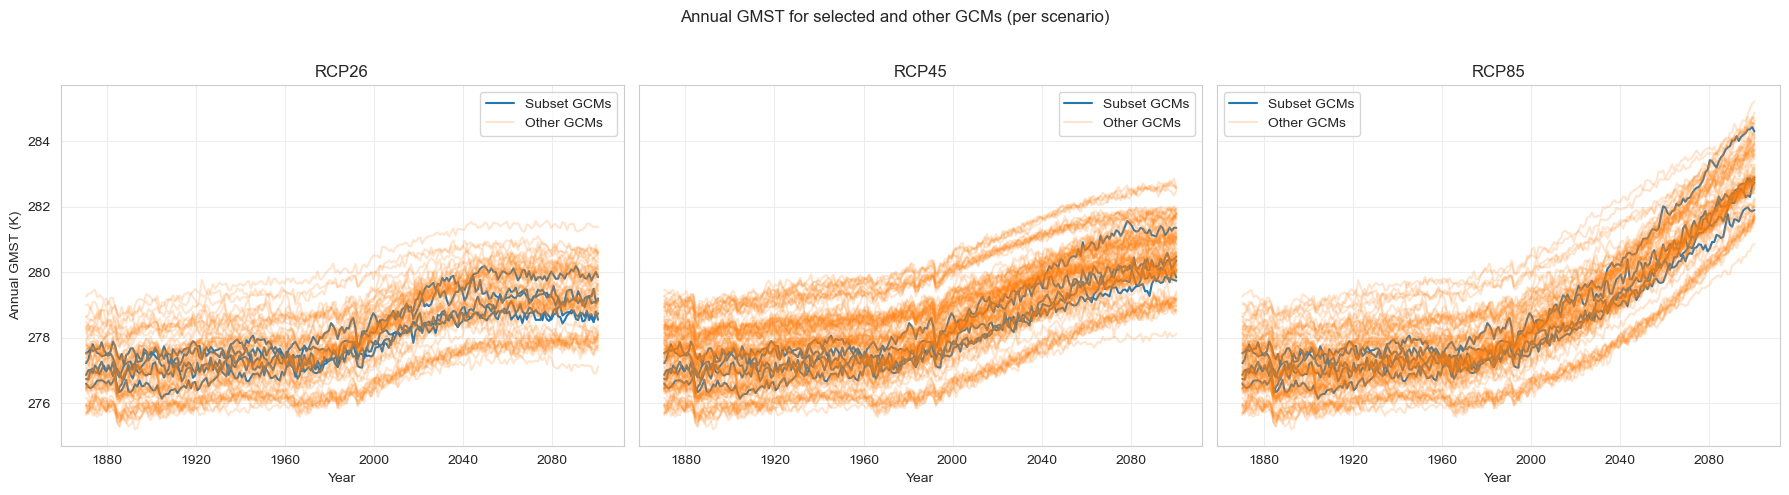

In [53]:
# Collect annual means for each file and scenario
annual_means = {sc: [] for sc in scenarios}
labels = {sc: [] for sc in scenarios}
colors = {sc: [] for sc in scenarios}
alphas = {sc: [] for sc in scenarios}

for sc in scenarios:
    for file_list, label, color, alpha in [
        (subset_gcms, "Subset GCMs", "tab:blue", 1.0),
        (all_other_gcms_data, "Other GCMs", "tab:orange", 0.2)
    ]:
        for file in file_list:
            if sc in file.name:
                ds = xr.open_dataset(file)
                mean = ds[var].mean(dim=["lat", "lon"]).values
                years = ds["year"].values if "year" in ds else np.arange(len(mean))
                annual_means[sc].append((years, mean))
                labels[sc].append(label)
                colors[sc].append(color)
                alphas[sc].append(alpha)
                ds.close()

fig, axes = plt.subplots(1, len(scenarios), figsize=(18, 5), sharey=True)

for i, sc in enumerate(scenarios):
    ax = axes[i]
    for (years, mean), label, color, alpha in zip(annual_means[sc], labels[sc], colors[sc], alphas[sc]):
        ax.plot(years, mean, color=color, alpha=alpha, label=label)
    handles, legend_labels = ax.get_legend_handles_labels()
    by_label = dict(zip(legend_labels, handles))
    ax.legend(by_label.values(), by_label.keys())
    ax.set_xlabel("Year")
    if i == 0:
        ax.set_ylabel("Annual GMST (K)")
    ax.set_title(sc.upper())

fig.suptitle("Annual GMST for selected and other GCMs (per scenario)")
plt.tight_layout(rect=[0, 0, 1, 0.96])
plt.show()
